# Assignment 7: Anomaly Detection – PDFs, Histograms, KDE, One-class SVM and Isolation Forest

## Introduction
In this assignment I apply several anomaly detection techniques from Lesson 7 to the NSL-KDD dataset, an improved version of the KDD Cup 1999 network intrusion dataset. Each row is a network connection described by 41 features (such as duration, protocol, service and the number of bytes sent), plus a label that says whether it was normal traffic or a specific type of attack.

I focus on HTTP (web) connections. I train every model only on normal HTTP traffic from the training set, and then check whether it can flag the attacks in the test set. This is novelty detection: the model learns what "normal" looks like, and anything that looks very different is treated as an anomaly. The labels are used only to evaluate the results.

My steps:
- Explain probability density functions and how they are used in anomaly detection (Task 1)
- Load the dataset and select the HTTP connections
- Create histograms and discuss their limitations (Task 2)
- Apply kernel density estimation (KDE) and compare different bandwidths (Task 3)
- Detect anomalies with a univariate KDE (Task 4)
- Detect HTTP attacks with a multivariate KDE (Task 5)
- Detect anomalies with a One-class SVM and compare it with KDE (Task 6)
- Detect anomalies with an Isolation Forest and compare all three methods (Task 7)

Note: the One-class SVM is slow on large datasets, so I trained it on a random sample of 10,000 normal HTTP connections.

## Task 1 – Probability Density Functions (PDFs)

### What a PDF is
A probability density function p(x) describes how likely the different values of a continuous variable are. Where the curve is high, values are common. Where it is low, values are rare.

### Basic properties
- p(x) is never negative: p(x) ≥ 0 for every x.
- The total area under the curve is 1, because the variable must take some value.
- p(x) itself is a density (a relative likelihood), not a probability. The actual probability that x falls between a and b is the area under the curve between a and b.
- For a single exact value, the probability is 0. Only ranges have a probability.
- A common example is the normal (Gaussian) distribution, which is fully described by its mean μ (the centre) and variance σ² (the spread).
- With several features, we use a joint PDF p(x, y, z). If the features are independent, it can be simplified to p(x) × p(y) × p(z).

### How PDFs are used in anomaly detection
- The main idea is that normal events are common and anomalies are rare. So normal samples fall where the density is high, and anomalies fall where the density is low.
- First I estimate the PDF of normal data (with a histogram, a fitted distribution or kernel density estimation).
- Then I choose a threshold. Any new sample with a density below the threshold is flagged as an anomaly.
- For example, if most normal web connections send between 200 and 2,000 bytes, a connection that sends 5,000,000 bytes falls in a very low-density area and is flagged as suspicious.
- The threshold controls the trade-off: a higher threshold catches more attacks but also creates more false alarms, while a lower threshold creates fewer false alarms but misses more attacks.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import norm
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, precision_score, recall_score, f1_score)

np.random.seed(42)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the NSL-KDD Dataset

In [2]:
col_names = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land",
             "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised",
             "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells",
             "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
             "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
             "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
             "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
             "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
             "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
             "label", "difficulty"]

train_df = pd.read_csv("KDDTrain.txt", header=None, names=col_names).drop(columns="difficulty")
test_df = pd.read_csv("KDDTest.txt", header=None, names=col_names).drop(columns="difficulty")
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Missing values – train:", train_df.isna().sum().sum(), "| test:", test_df.isna().sum().sum())
display(train_df.head(3))

http_train = train_df[train_df["service"] == "http"].copy()
http_test = test_df[test_df["service"] == "http"].copy()
http_train["is_attack"] = (http_train["label"] != "normal").astype(int)
http_test["is_attack"] = (http_test["label"] != "normal").astype(int)

print("\nHTTP train:", http_train.shape, "| HTTP test:", http_test.shape)
print("\nHTTP train labels:\n", http_train["label"].value_counts().to_string())
print("\nHTTP test labels:\n", http_test["label"].value_counts().to_string())
print("\nAttack types in test but NOT in train:",
      sorted(set(http_test["label"]) - set(http_train["label"])))

Train: (125973, 42) | Test: (22544, 42)
Missing values – train: 0 | test: 0


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.0,150,25,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.0,255,1,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.0,255,26,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune



HTTP train: (40338, 43) | HTTP test: (7853, 43)

HTTP train labels:
 label
normal       38049
neptune       1299
back           956
portsweep       15
ipsweep          7
satan            7
phf              4
nmap             1

HTTP test labels:
 label
normal       6673
apache2       737
back          359
neptune        79
portsweep       2
phf             2
saint           1

Attack types in test but NOT in train: ['apache2', 'saint']


### Interpretation – Loading the Data
- The training set has 125,973 connections and the test set has 22,544, each with 41 features plus the label (after removing the difficulty column). There are no missing values.
- I kept only HTTP (web) connections: 40,338 in the training set and 7,853 in the test set.
- In the HTTP training data, 38,049 connections are normal (94.3%) and only 2,289 are attacks (5.7%), mostly neptune (1,299) and back (956). This strong imbalance is typical for anomaly detection, where anomalies are rare.
- In the HTTP test data, 6,673 connections are normal (85.0%) and 1,180 are attacks (15.0%), mostly apache2 (737), back (359) and neptune (79).
- The attack types apache2 and saint appear only in the test set. This means 738 of the 1,180 test attacks (62.5%) are types the models have never seen during training. This is a realistic novelty detection test, because in real life new kinds of attacks keep appearing.
- I will train the models only on the normal HTTP connections from the training set, so they learn what normal web traffic looks like, and then check how well they flag the attacks in the test set.

## 3. Histograms and Their Limitations 

In [3]:
for df in [http_train, http_test]:
    df["log_duration"] = np.log1p(df["duration"])
    df["log_src_bytes"] = np.log1p(df["src_bytes"])
    df["log_dst_bytes"] = np.log1p(df["dst_bytes"])

normal_train = http_train[http_train["is_attack"] == 0]
attack_test = http_test[http_test["is_attack"] == 1]

print("src_bytes – normal HTTP (train):")
print(normal_train["src_bytes"].describe().round(1).to_string())

src_bytes – normal HTTP (train):
count    38049.0
mean       243.7
std        318.3
min          0.0
25%        210.0
50%        241.0
75%        303.0
max      54540.0


In [4]:
counts, edges = np.histogram(normal_train["log_src_bytes"], bins="auto")
print(f"\nbins='auto' chose {len(counts)} bins")


bins='auto' chose 391 bins


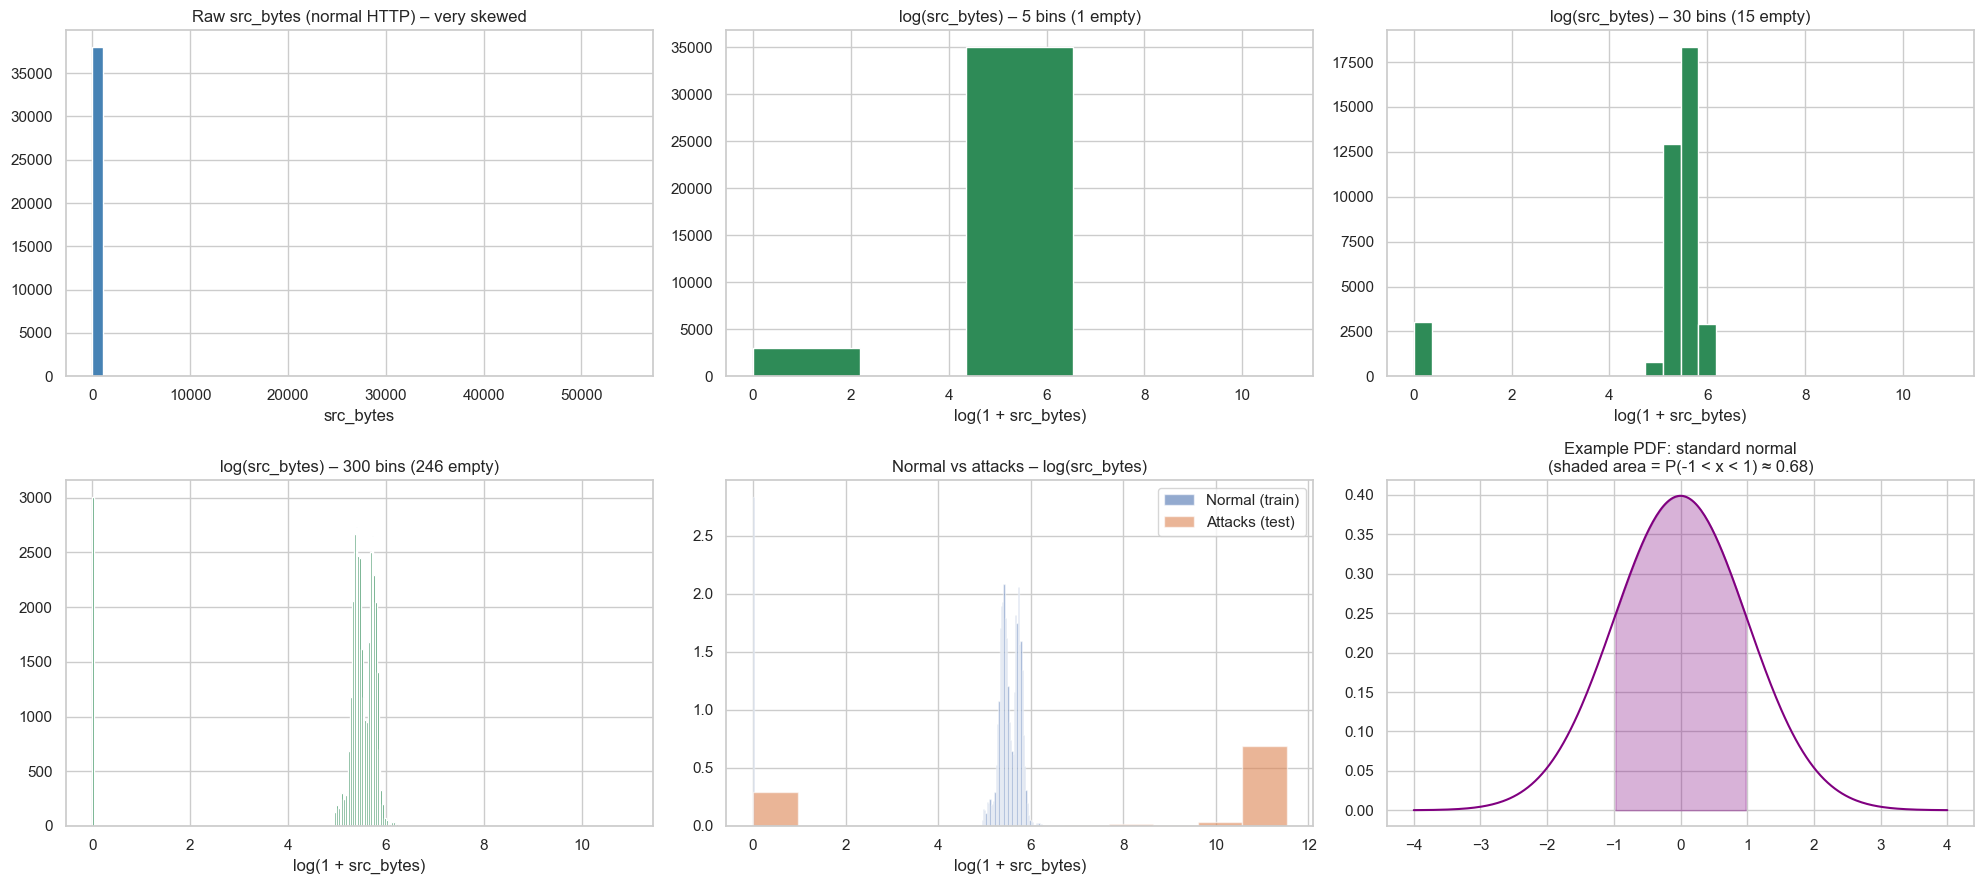

Most common bin: log(src_bytes) between 0.00 and 0.03 → probability ≈ 0.079


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
axes = axes.flatten()

axes[0].hist(normal_train["src_bytes"], bins=50, color="steelblue")
axes[0].set_title("Raw src_bytes (normal HTTP) – very skewed")
axes[0].set_xlabel("src_bytes")

for ax, b in zip(axes[1:4], [5, 30, 300]):
    c, _, _ = ax.hist(normal_train["log_src_bytes"], bins=b, color="seagreen")
    ax.set_title(f"log(src_bytes) – {b} bins ({(c == 0).sum()} empty)")
    ax.set_xlabel("log(1 + src_bytes)")

axes[4].hist(normal_train["log_src_bytes"], bins="auto", density=True, alpha=0.6, label="Normal (train)")
axes[4].hist(attack_test["log_src_bytes"], bins="auto", density=True, alpha=0.6, label="Attacks (test)")
axes[4].set_title("Normal vs attacks – log(src_bytes)")
axes[4].set_xlabel("log(1 + src_bytes)")
axes[4].legend()

x = np.linspace(-4, 4, 300)
axes[5].plot(x, norm.pdf(x), color="purple")
axes[5].fill_between(x, norm.pdf(x), where=(x > -1) & (x < 1), alpha=0.3, color="purple")
axes[5].set_title("Example PDF: standard normal\n(shaded area = P(-1 < x < 1) ≈ 0.68)")
plt.tight_layout(); plt.show()

idx = np.argmax(counts)
print(f"Most common bin: log(src_bytes) between {edges[idx]:.2f} and {edges[idx+1]:.2f} "
      f"→ probability ≈ {counts[idx] / counts.sum():.3f}")

## Task 2 – Histograms and Their Limitations

### What the histograms show
- Normal HTTP connections send a very consistent amount of data: the median is 241 bytes and half of all connections send between 210 and 303 bytes. However, the maximum is 54,540 bytes, so there is a long tail of rare large values.
- The raw histogram shows almost everything in one bar because a few very large values stretch the axis. After a log transform, two groups appear: a main peak around 200 to 330 bytes and a smaller group at exactly 0 bytes (connections that sent no data).
- Comparing normal training traffic with test attacks, the attacks are at the two extremes: around 0 bytes (for example, neptune connections that never complete) and around 36,000 to 60,000 bytes (the very large requests used by the back and apache2 attacks). Normal traffic sits in the middle, so unusually small or unusually large requests are suspicious.
- About 8% of normal connections also send 0 bytes, the same as the neptune attacks, so this feature alone cannot separate those cases.
- A histogram can approximate probabilities: the probability of a bin is its count divided by the total. For example, the most common bin with automatic bin selection has a probability of about 0.079.

### Limitations of histograms for anomaly detection
- The result depends heavily on the number and width of bins. With 5 bins the histogram is too rough and hides the structure. With 300 bins it becomes spiky and sparse, with 246 empty bins.
- Empty bins give a probability of zero. A normal value that falls into an empty bin would wrongly look impossible and be flagged as an anomaly.
- Histograms are not smooth. The density jumps at bin edges, so two almost identical values can get very different probabilities if they fall into different bins.
- Choosing bins automatically (bins='auto' chose 391 bins) can also be misleading. Here the most common bin is 0 bytes, even though the real centre of normal traffic is about 241 bytes, because all zero-byte connections fall into one bin while the main group is split across many narrow bins.
- Histograms become impractical with several features, because the number of bins grows very quickly (for example, 30 bins per feature means 27,000 bins for 3 features), and most of them would be empty.
- Because of these problems, kernel density estimation (KDE) is a better way to estimate the density for anomaly detection.

## 4. Kernel Density Estimation and Bandwidth Selection

Best bandwidth (5-fold cross-validation): 0.083
Scott's rule: 0.121 | Silverman's rule: 0.129


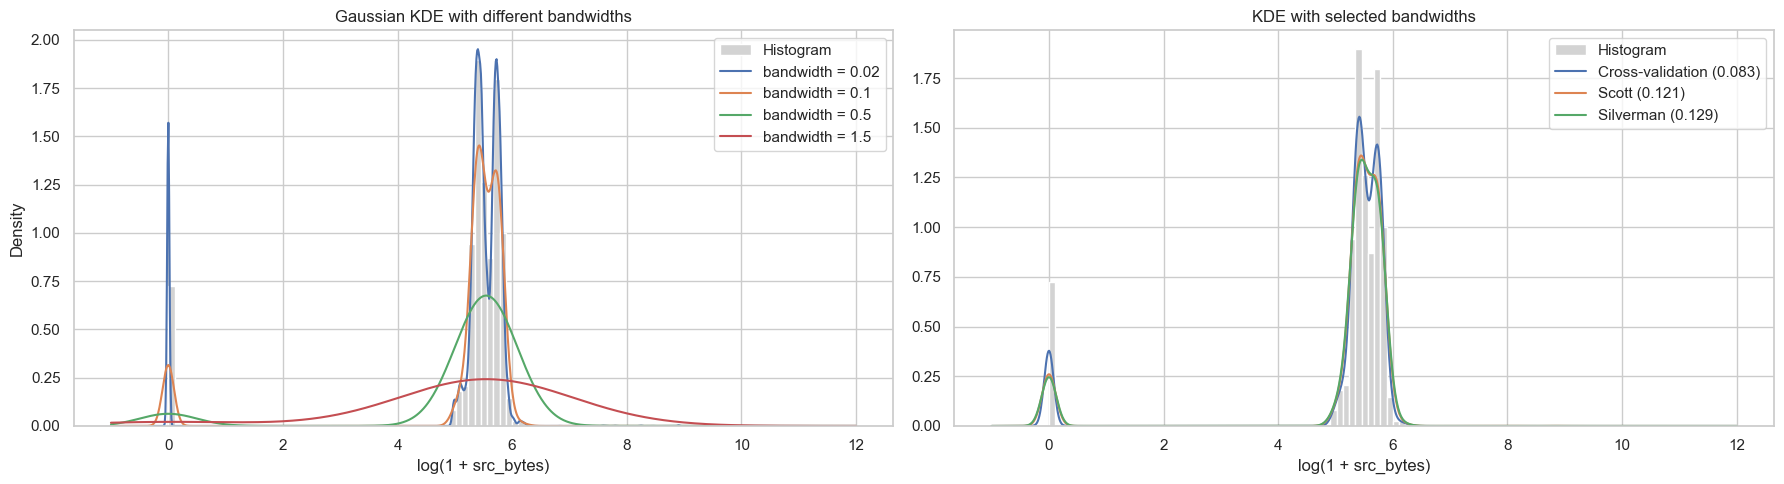

In [6]:
x_normal = normal_train["log_src_bytes"].values.reshape(-1, 1)
x_grid = np.linspace(-1, 12, 1000).reshape(-1, 1)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].hist(x_normal, bins=100, density=True, color="lightgrey", label="Histogram")
for bw in [0.02, 0.1, 0.5, 1.5]:
    kde_bw = KernelDensity(kernel="gaussian", bandwidth=bw).fit(x_normal)
    axes[0].plot(x_grid, np.exp(kde_bw.score_samples(x_grid)), label=f"bandwidth = {bw}")
axes[0].set_title("Gaussian KDE with different bandwidths")
axes[0].set_xlabel("log(1 + src_bytes)"); axes[0].set_ylabel("Density"); axes[0].legend()

rng = np.random.default_rng(42)
x_sample = x_normal[rng.choice(len(x_normal), 5000, replace=False)]
grid = GridSearchCV(KernelDensity(kernel="gaussian"),
                    {"bandwidth": np.logspace(-2, 0.5, 20)}, cv=5)
grid.fit(x_sample)
bw_cv = grid.best_params_["bandwidth"]

bw_scott = KernelDensity(bandwidth="scott").fit(x_normal).bandwidth_
bw_silverman = KernelDensity(bandwidth="silverman").fit(x_normal).bandwidth_
print(f"Best bandwidth (5-fold cross-validation): {bw_cv:.3f}")
print(f"Scott's rule: {bw_scott:.3f} | Silverman's rule: {bw_silverman:.3f}")

axes[1].hist(x_normal, bins=100, density=True, color="lightgrey", label="Histogram")
for bw, name in [(bw_cv, "Cross-validation"), (bw_scott, "Scott"), (bw_silverman, "Silverman")]:
    kde_sel = KernelDensity(kernel="gaussian", bandwidth=bw).fit(x_normal)
    axes[1].plot(x_grid, np.exp(kde_sel.score_samples(x_grid)), label=f"{name} ({bw:.3f})")
axes[1].set_title("KDE with selected bandwidths")
axes[1].set_xlabel("log(1 + src_bytes)"); axes[1].legend()
plt.tight_layout(); plt.show()

## Task 3 – Kernel Density Estimation and Bandwidth Selection
- KDE places a small smooth bump (here a Gaussian kernel) on every training value and adds them up to get a continuous density curve. Unlike a histogram, it has no bins, so the density changes smoothly and there are no empty gaps.
- The bandwidth is the width of each bump and it controls how smooth the curve is:
  - With bandwidth = 0.02 the curve is very spiky, with tall narrow peaks and a huge spike at 0. It overfits the training data.
  - With bandwidth = 0.1 the curve shows the real structure: a small group at 0 bytes and a main group with two close peaks (around log values 5.4 and 5.7, about 220 and 300 bytes).
  - With bandwidth = 0.5 the curve becomes one wide bell and the 0-byte group almost disappears.
  - With bandwidth = 1.5 the curve is very flat and wide, and it even gives some density to values around 10 to 11, where the large attack requests are. Attacks would then look normal.
- I compared three ways to choose the bandwidth. 5-fold cross-validation (which picks the bandwidth that gives the highest likelihood on held-out data) chose 0.083, Scott's rule gave 0.121, and Silverman's rule gave 0.129. All three keep the main structure. Cross-validation keeps the most detail, while the two rules of thumb smooth the two peaks together slightly because they assume a roughly bell-shaped distribution.
- Bandwidth selection is important for anomaly detection because it decides where the density becomes low. A bandwidth that is too large can hide real anomalies (missed attacks), while one that is too small can flag normal but slightly unusual values (false alarms). I use the cross-validated bandwidth of 0.083 for the next step.

## 5. Univariate Anomaly Detection with KDE

In [7]:
kde_uni = KernelDensity(kernel="gaussian", bandwidth=bw_cv).fit(x_normal)

log_dens_train = kde_uni.score_samples(x_normal)
threshold_uni = np.percentile(log_dens_train, 1)
print(f"Threshold: log-density {threshold_uni:.3f} (density {np.exp(threshold_uni):.5f}) "
      f"= 1st percentile of normal training data")

Threshold: log-density -2.302 (density 0.10005) = 1st percentile of normal training data


In [8]:
x_test_uni = http_test["log_src_bytes"].values.reshape(-1, 1)
y_test = http_test["is_attack"].values
log_dens_test = kde_uni.score_samples(x_test_uni)
pred_uni = (log_dens_test < threshold_uni).astype(int)

print(f"\nROC AUC (lower density = more anomalous): {roc_auc_score(y_test, -log_dens_test):.4f}\n")
print(classification_report(y_test, pred_uni, target_names=["normal", "attack"], digits=3))

print("Share flagged as anomaly, by true label:")
display(http_test.assign(flagged=pred_uni).groupby("label")["flagged"]
        .agg(connections="count", flagged_pct="mean").assign(flagged_pct=lambda d: (d["flagged_pct"] * 100).round(1)))



ROC AUC (lower density = more anomalous): 0.9844

              precision    recall  f1-score   support

      normal      0.953     0.992     0.972      6673
      attack      0.939     0.721     0.816      1180

    accuracy                          0.951      7853
   macro avg      0.946     0.856     0.894      7853
weighted avg      0.951     0.951     0.948      7853

Share flagged as anomaly, by true label:


,connections,flagged_pct
label,,
apache2,737,66.6
back,359,100.0
neptune,79,0.0
normal,6673,0.8
phf,2,50.0
portsweep,2,0.0
saint,1,0.0


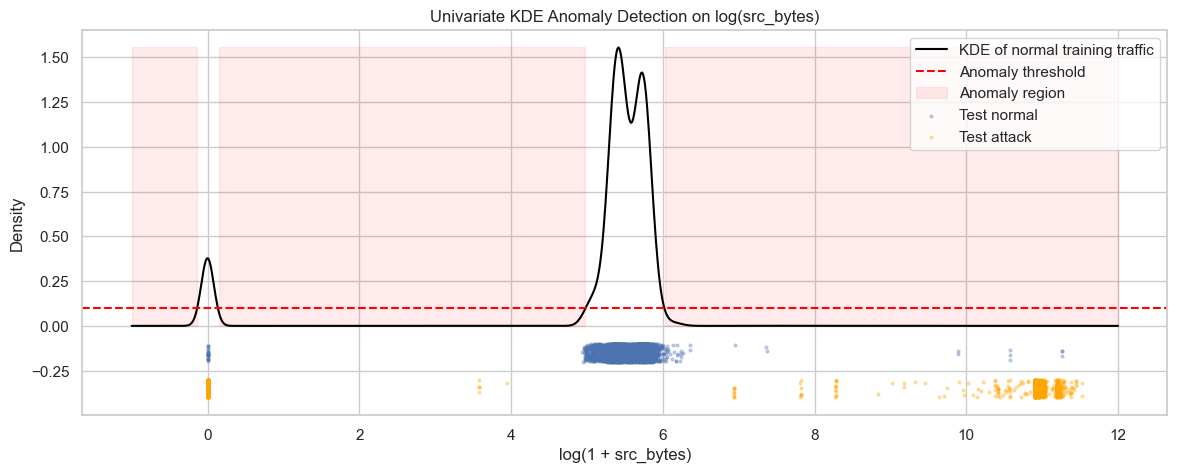

In [9]:
dens_grid = np.exp(kde_uni.score_samples(x_grid))
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(x_grid, dens_grid, color="black", label="KDE of normal training traffic")
ax.axhline(np.exp(threshold_uni), color="red", linestyle="--", label="Anomaly threshold")
ax.fill_between(x_grid.ravel(), 0, dens_grid.max(), where=dens_grid < np.exp(threshold_uni),
                color="red", alpha=0.08, label="Anomaly region")
jitter = rng.uniform(-0.05, 0.05, len(y_test))
ax.scatter(x_test_uni[y_test == 0], -0.15 + jitter[y_test == 0], s=4, alpha=0.3, label="Test normal")
ax.scatter(x_test_uni[y_test == 1], -0.35 + jitter[y_test == 1], s=4, alpha=0.3, color="orange", label="Test attack")
ax.set_title("Univariate KDE Anomaly Detection on log(src_bytes)")
ax.set_xlabel("log(1 + src_bytes)"); ax.set_ylabel("Density"); ax.legend(loc="upper right")
plt.show()

## Task 4 – Univariate Anomaly Detection with KDE
- I fitted a Gaussian KDE (bandwidth 0.083) on log(src_bytes) using only normal HTTP training connections. I set the anomaly threshold at the 1st percentile of the training densities (a density of about 0.100), so about 1% of normal training traffic falls below it. Any test connection with a lower density than this is flagged as an anomaly.
- In the plot, the black curve is the density of normal traffic and the light red areas are where the density is below the threshold. Normal traffic is concentrated around 200 to 400 bytes, plus a small group at 0 bytes.
- Results on the HTTP test set:
  - ROC AUC = 0.984, so the density ranks attacks below normal traffic very well, even with only one feature.
  - 72.1% of attacks were caught (recall), and 93.9% of the alarms were real attacks (precision).
  - Only 0.8% of normal connections were wrongly flagged, close to the 1% I designed with the threshold.
- By attack type:
  - All 359 back attacks were caught (100%). Their requests are extremely large (about 36,000 to 100,000 bytes), which falls far into the low-density region.
  - 66.6% of the apache2 attacks were caught, even though this attack type never appeared in the training data. This shows that KDE can detect new kinds of attacks, as long as they look different from normal traffic.
  - None of the neptune attacks were caught (0%), and the same happened for portsweep and saint. These connections send 0 bytes, which falls inside the small 0-byte group of normal traffic, so their density is above the threshold.
- KDE helps identify anomalies because it gives a smooth estimate of how likely each value is for normal traffic, with no empty bins, so rare values can be measured and compared with a threshold. However, a single feature can only catch attacks that are unusual on that feature. To catch the 0-byte attacks, I need more features, which I add in the next task.

## 6. HTTP Attack Detection with Multivariate KDE

In [10]:
features = ["log_duration", "log_src_bytes", "log_dst_bytes"]
scaler = StandardScaler().fit(normal_train[features])
X_normal = scaler.transform(normal_train[features])
X_test = scaler.transform(http_test[features])

x_sample3 = X_normal[rng.choice(len(X_normal), 5000, replace=False)]
grid3 = GridSearchCV(KernelDensity(kernel="gaussian"), {"bandwidth": np.logspace(-2, 0, 20)}, cv=5)
grid3.fit(x_sample3)
bw3 = grid3.best_params_["bandwidth"]
print(f"Best bandwidth (3 features, cross-validation): {bw3:.3f}")

Best bandwidth (3 features, cross-validation): 0.070


In [11]:
kde_multi = KernelDensity(kernel="gaussian", bandwidth=bw3).fit(X_normal)
threshold_multi = np.percentile(kde_multi.score_samples(X_normal), 1)
kde_scores = kde_multi.score_samples(X_test)
pred_kde = (kde_scores < threshold_multi).astype(int)

print(f"ROC AUC: {roc_auc_score(y_test, -kde_scores):.4f}\n")
print(classification_report(y_test, pred_kde, target_names=["normal", "attack"], digits=3))
display(http_test.assign(flagged=pred_kde).groupby("label")["flagged"]
        .agg(connections="count", flagged_pct="mean").assign(flagged_pct=lambda d: (d["flagged_pct"] * 100).round(1)))

ROC AUC: 0.7195

              precision    recall  f1-score   support

      normal      0.953     0.991     0.971      6673
      attack      0.932     0.721     0.813      1180

    accuracy                          0.950      7853
   macro avg      0.942     0.856     0.892      7853
weighted avg      0.950     0.950     0.948      7853



,connections,flagged_pct
label,,
apache2,737,66.6
back,359,100.0
neptune,79,0.0
normal,6673,0.9
phf,2,50.0
portsweep,2,0.0
saint,1,0.0


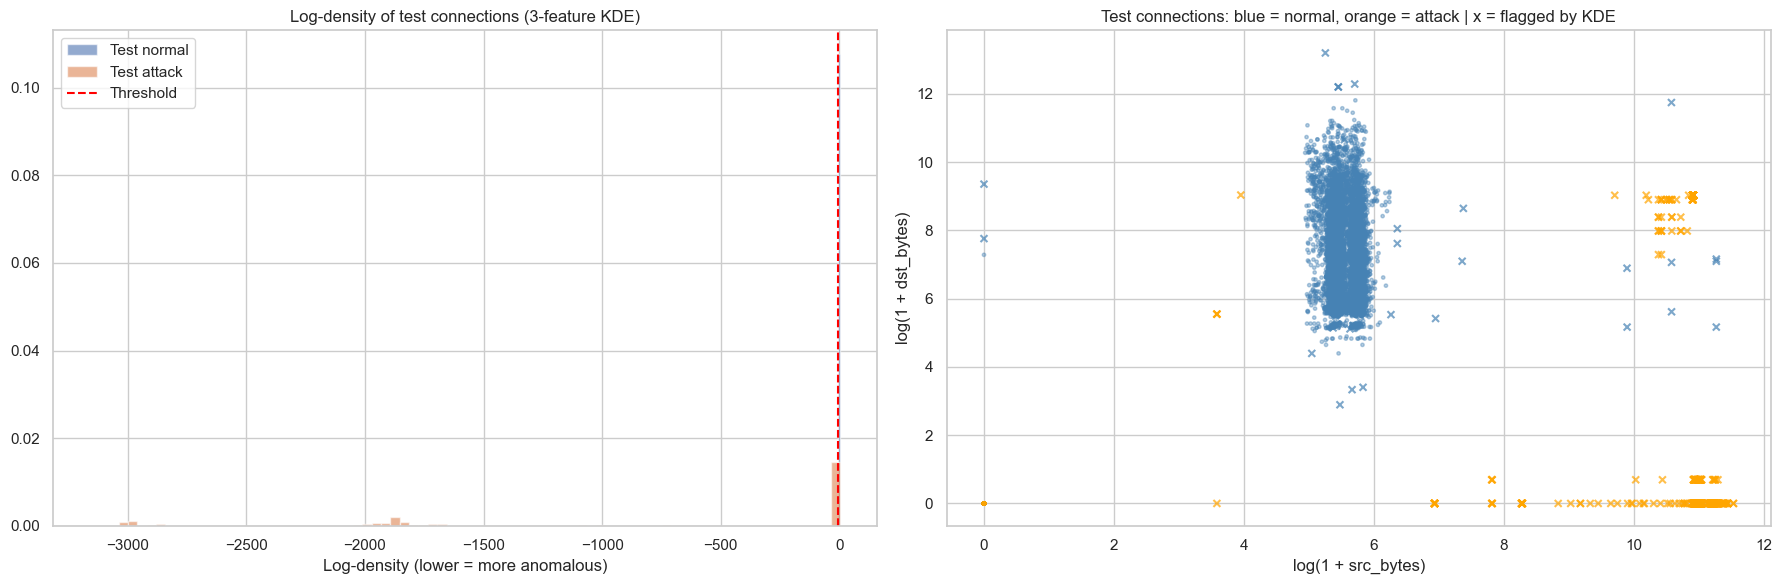

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].hist(kde_scores[y_test == 0], bins=80, alpha=0.6, density=True, label="Test normal")
axes[0].hist(kde_scores[y_test == 1], bins=80, alpha=0.6, density=True, label="Test attack")
axes[0].axvline(threshold_multi, color="red", linestyle="--", label="Threshold")
axes[0].set_title("Log-density of test connections (3-feature KDE)")
axes[0].set_xlabel("Log-density (lower = more anomalous)"); axes[0].legend()

colors = np.where(y_test == 1, "orange", "steelblue")
markers_flag = pred_kde == 1
axes[1].scatter(http_test["log_src_bytes"][~markers_flag], http_test["log_dst_bytes"][~markers_flag],
                c=colors[~markers_flag], s=6, alpha=0.4, marker="o")
axes[1].scatter(http_test["log_src_bytes"][markers_flag], http_test["log_dst_bytes"][markers_flag],
                c=colors[markers_flag], s=25, alpha=0.7, marker="x")
axes[1].set_title("Test connections: blue = normal, orange = attack | x = flagged by KDE")
axes[1].set_xlabel("log(1 + src_bytes)"); axes[1].set_ylabel("log(1 + dst_bytes)")
plt.tight_layout(); plt.show()

## Task 5 – HTTP Attack Detection with Multivariate KDE
- I used three log-transformed features (duration, bytes sent and bytes received), scaled using normal training traffic only. Cross-validation chose a bandwidth of 0.070. As before, the threshold is the 1st percentile of the densities of normal training connections.
- The 3-feature KDE caught exactly the same attacks as the univariate KDE: 72.1% of attacks overall, including all back attacks (100%) and 66.6% of the unseen apache2 attacks, but none of the neptune, portsweep or saint attacks. Precision was 93.2% and only 0.9% of normal connections were wrongly flagged.
- However, the ROC AUC dropped from 0.984 (univariate) to 0.720. The scatter plot explains why. The missed neptune attacks have 0 duration, 0 bytes sent and 0 bytes received. Some normal training connections have exactly the same values (0, 0, 0). Many identical points in one spot, combined with a small bandwidth, create a very tall and narrow density spike there. So these attacks get a very high density, likely even higher than most real normal traffic, and they are ranked as the most normal connections of all, which lowers the AUC.
- In the scatter plot, normal traffic forms one dense cloud (about 200 to 400 bytes sent and 150 to 20,000 bytes received). The flagged attacks are mostly the very large requests on the right (back and apache2), and the few flagged normal connections are unusual points far from the main cloud.
- In the log-density histogram, the detected attacks have extremely low log-densities (some around -2,000 to -3,000), far below the threshold, while the missed attacks sit with the normal traffic.
- This shows an important limitation of KDE: it assumes continuous data. When many samples share exactly the same value (like many exact zeros), the density gets artificial spikes that can hide anomalies. Adding more features does not automatically help if they do not separate the attacks from normal traffic.

## 7. One-class SVM

In [13]:
print("Median log-density – normal:", round(np.median(kde_scores[y_test == 0]), 2),
      "| neptune:", round(np.median(kde_scores[http_test["label"].values == "neptune"]), 2))

X_normal_sample = X_normal[rng.choice(len(X_normal), 10000, replace=False)]

nu_rows = []
for nu in [0.01, 0.05, 0.1]:
    oc = OneClassSVM(kernel="rbf", gamma="scale", nu=nu).fit(X_normal_sample)
    p = (oc.predict(X_test) == -1).astype(int)
    nu_rows.append({"nu": nu, "recall_attack": round(recall_score(y_test, p), 3),
                    "precision_attack": round(precision_score(y_test, p), 3),
                    "normal_flagged_%": round(p[y_test == 0].mean() * 100, 1)})
print(pd.DataFrame(nu_rows).to_string(index=False))

Median log-density – normal: 1.75 | neptune: 2.67
  nu  recall_attack  precision_attack  normal_flagged_%
0.01          0.721             0.945               0.7
0.05          1.000             0.792               4.6
0.10          0.721             0.620               7.8


In [14]:
ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.01).fit(X_normal_sample)
ocsvm_scores = ocsvm.decision_function(X_test)
pred_ocsvm = (ocsvm.predict(X_test) == -1).astype(int)

print(f"\nOne-class SVM (nu = 0.01) – ROC AUC: {roc_auc_score(y_test, -ocsvm_scores):.4f}\n")
print(classification_report(y_test, pred_ocsvm, target_names=["normal", "attack"], digits=3))
display(http_test.assign(flagged=pred_ocsvm).groupby("label")["flagged"]
        .agg(connections="count", flagged_pct="mean").assign(flagged_pct=lambda d: (d["flagged_pct"] * 100).round(1)))

print("KDE vs One-class SVM flags (rows = KDE, columns = OCSVM):")
display(pd.crosstab(pred_kde, pred_ocsvm, rownames=["KDE"], colnames=["OCSVM"]))


One-class SVM (nu = 0.01) – ROC AUC: 0.9973

              precision    recall  f1-score   support

      normal      0.953     0.993     0.972      6673
      attack      0.945     0.721     0.818      1180

    accuracy                          0.952      7853
   macro avg      0.949     0.857     0.895      7853
weighted avg      0.951     0.952     0.949      7853



,connections,flagged_pct
label,,
apache2,737,66.6
back,359,100.0
neptune,79,0.0
normal,6673,0.7
phf,2,50.0
portsweep,2,0.0
saint,1,0.0


KDE vs One-class SVM flags (rows = KDE, columns = OCSVM):


OCSVM,0,1
KDE,,
0,6936,4
1,16,897


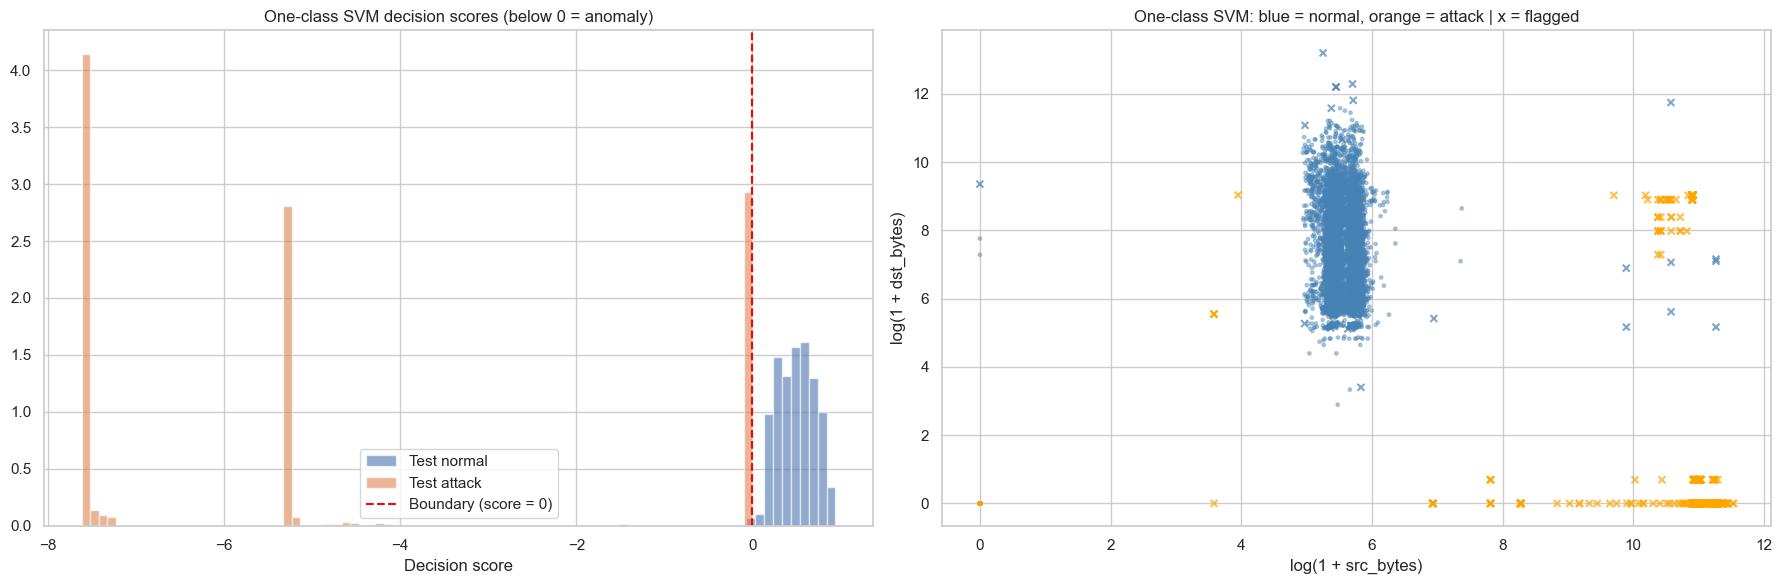

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].hist(ocsvm_scores[y_test == 0], bins=80, alpha=0.6, density=True, label="Test normal")
axes[0].hist(ocsvm_scores[y_test == 1], bins=80, alpha=0.6, density=True, label="Test attack")
axes[0].axvline(0, color="red", linestyle="--", label="Boundary (score = 0)")
axes[0].set_title("One-class SVM decision scores (below 0 = anomaly)")
axes[0].set_xlabel("Decision score"); axes[0].legend()

flag = pred_ocsvm == 1
axes[1].scatter(http_test["log_src_bytes"][~flag], http_test["log_dst_bytes"][~flag], c=colors[~flag], s=6, alpha=0.4)
axes[1].scatter(http_test["log_src_bytes"][flag], http_test["log_dst_bytes"][flag], c=colors[flag], s=25, alpha=0.7, marker="x")
axes[1].set_title("One-class SVM: blue = normal, orange = attack | x = flagged")
axes[1].set_xlabel("log(1 + src_bytes)"); axes[1].set_ylabel("log(1 + dst_bytes)")
plt.tight_layout(); plt.show()

## Task 6 – One-class SVM and Comparison with KDE
- First I checked my explanation of the low KDE AUC: the median log-density of neptune attacks (2.67) is higher than that of normal test traffic (1.75). This confirms that the 0-byte neptune connections fall on a high-density spike created by identical normal connections, so the KDE treats them as very normal.
- The One-class SVM learns a boundary around the normal training data, using an RBF kernel so the boundary can be curved. I trained it on a random sample of 10,000 normal HTTP connections because the One-class SVM becomes very slow on large datasets.
- The parameter nu controls roughly what share of the training data may fall outside the boundary:
  - With nu = 0.01, it caught 72.1% of attacks with 94.5% precision, and flagged only 0.7% of normal traffic.
  - With nu = 0.05, it caught 100% of attacks, including all the 0-byte neptune, portsweep and saint attacks, but precision dropped to 79.2% and 4.6% of normal traffic was flagged.
  - With nu = 0.10, recall dropped back to 72.1% while 7.8% of normal traffic was flagged. The shape of the boundary changes with nu, and here the 0-byte group ended up inside the boundary again. This shows that the One-class SVM is very sensitive to nu, and the effect is not always predictable.
- I used nu = 0.01 as my main model, so it matches the 1% threshold I used for KDE. It caught exactly the same attack types as the KDE: all back attacks, 66.6% of the unseen apache2 attacks, and no neptune, portsweep or saint attacks.
- The two models agreed on 99.7% of test connections (6,936 normal and 897 flagged by both). Only 16 connections were flagged by KDE alone and 4 by the One-class SVM alone.
- The biggest difference is the ROC AUC: 0.997 for the One-class SVM versus 0.720 for the 3-feature KDE. In the decision score plot, normal traffic has scores between about 0 and 1, the detected attacks are far outside the boundary (around -5.3 and -7.5), and the missed 0-byte attacks sit right at the boundary (a score of about 0). So the One-class SVM still ranks these attacks as more suspicious than almost all normal traffic, even though they do not cross the boundary at nu = 0.01. The KDE, on the other hand, ranked them as more normal than normal traffic.
- Overall, the One-class SVM gave the same detections as KDE at the chosen threshold, slightly better precision and far better ranking, and it handled the repeated zero values much better. Its downsides are that it is slow on large datasets (I needed a sample) and very sensitive to nu.

## 8. Isolation Forest and Final Comparison

In [16]:
isf = IsolationForest(n_estimators=200, contamination=0.01, random_state=42)
isf.fit(X_normal)
isf_scores = isf.score_samples(X_test)
pred_isf = (isf.predict(X_test) == -1).astype(int)

print(f"Isolation Forest – ROC AUC: {roc_auc_score(y_test, -isf_scores):.4f}\n")
print(classification_report(y_test, pred_isf, target_names=["normal", "attack"], digits=3))

models = {"KDE (1 feature)": (pred_uni, -log_dens_test),
          "KDE (3 features)": (pred_kde, -kde_scores),
          "One-class SVM": (pred_ocsvm, -ocsvm_scores),
          "Isolation Forest": (pred_isf, -isf_scores)}

summary = pd.DataFrame({name: {"ROC_AUC": roc_auc_score(y_test, s),
                               "recall_attack": recall_score(y_test, p),
                               "precision_attack": precision_score(y_test, p),
                               "F1_attack": f1_score(y_test, p),
                               "normal_flagged_%": p[y_test == 0].mean() * 100}
                        for name, (p, s) in models.items()}).T.round(3)
display(summary)

by_label = pd.DataFrame({name: http_test.assign(f=p).groupby("label")["f"].mean().mul(100).round(1)
                         for name, (p, s) in models.items()})
print("Detection rate (%) by true label:")
display(by_label)

Isolation Forest – ROC AUC: 0.9951

              precision    recall  f1-score   support

      normal      0.909     0.993     0.950      6673
      attack      0.922     0.440     0.596      1180

    accuracy                          0.910      7853
   macro avg      0.916     0.717     0.773      7853
weighted avg      0.911     0.910     0.896      7853



,ROC_AUC,recall_attack,precision_attack,F1_attack,normal_flagged_%
KDE (1 feature),0.984,0.721,0.939,0.816,0.824
KDE (3 features),0.719,0.721,0.932,0.813,0.929
One-class SVM,0.997,0.721,0.945,0.818,0.749
Isolation Forest,0.995,0.440,0.922,0.596,0.659


Detection rate (%) by true label:


,KDE (1 feature),KDE (3 features),One-class SVM,Isolation Forest
label,,,,
apache2,66.6,66.6,66.6,66.4
back,100.0,100.0,100.0,8.4
neptune,0.0,0.0,0.0,0.0
normal,0.8,0.9,0.7,0.7
phf,50.0,50.0,50.0,0.0
portsweep,0.0,0.0,0.0,0.0
saint,0.0,0.0,0.0,0.0


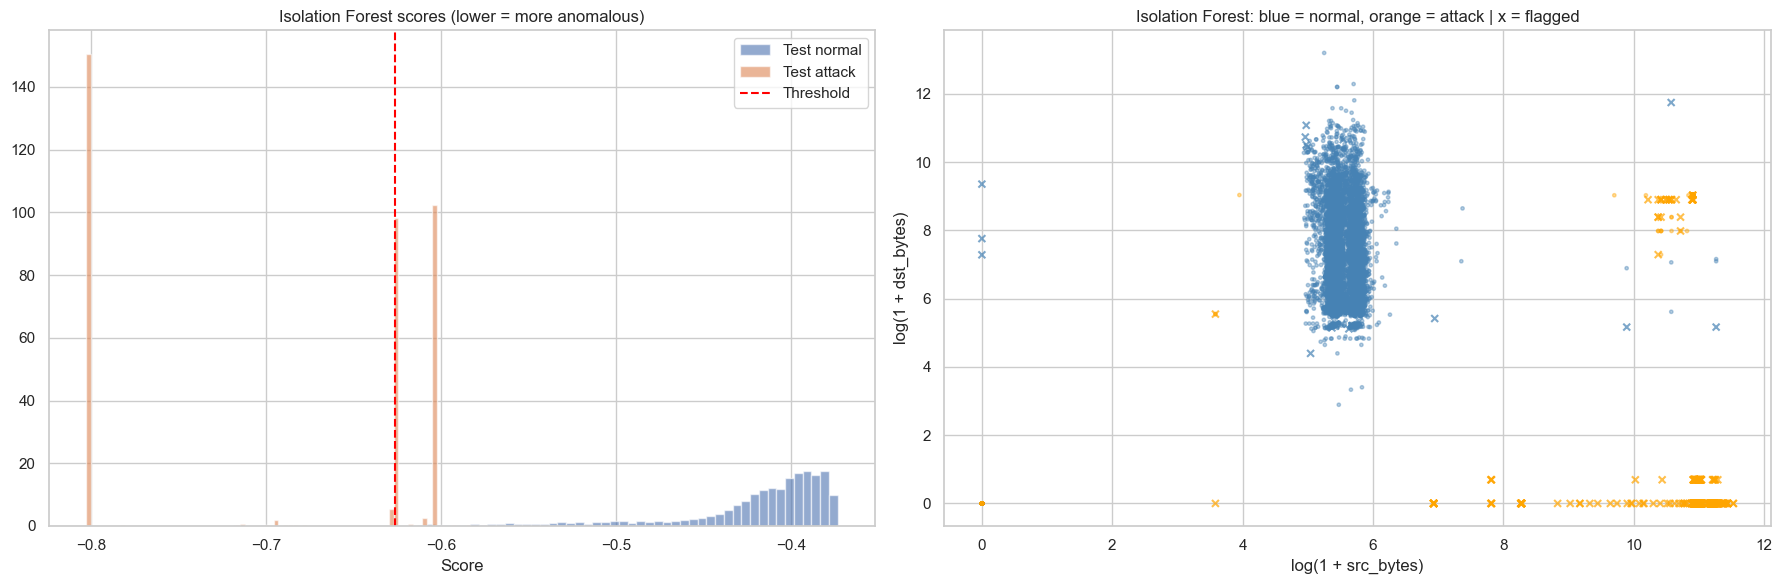

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].hist(isf_scores[y_test == 0], bins=80, alpha=0.6, density=True, label="Test normal")
axes[0].hist(isf_scores[y_test == 1], bins=80, alpha=0.6, density=True, label="Test attack")
axes[0].axvline(isf.offset_, color="red", linestyle="--", label="Threshold")
axes[0].set_title("Isolation Forest scores (lower = more anomalous)")
axes[0].set_xlabel("Score"); axes[0].legend()

flag = pred_isf == 1
axes[1].scatter(http_test["log_src_bytes"][~flag], http_test["log_dst_bytes"][~flag], c=colors[~flag], s=6, alpha=0.4)
axes[1].scatter(http_test["log_src_bytes"][flag], http_test["log_dst_bytes"][flag], c=colors[flag], s=25, alpha=0.7, marker="x")
axes[1].set_title("Isolation Forest: blue = normal, orange = attack | x = flagged")
axes[1].set_xlabel("log(1 + src_bytes)"); axes[1].set_ylabel("log(1 + dst_bytes)")
plt.tight_layout(); plt.show()

## Task 7 – Isolation Forest and Comparison of All Methods

### Isolation Forest
- Isolation Forest builds many random trees and isolates each connection with random splits. Anomalies are rare and different, so they are isolated in fewer splits and get lower scores. I trained it on all 38,049 normal HTTP connections (it is fast enough for the full data) with 200 trees and contamination = 0.01, so the threshold flags about 1% of normal training traffic, the same as the other methods.
- Its ROC AUC was 0.995, almost as high as the One-class SVM, and it flagged the fewest normal connections (0.66%). However, it caught only 44.0% of attacks.
- The score plot explains this. The apache2 attacks have very low scores (around -0.8) and were flagged (66.4%). The back attacks form a tall group at about -0.61, just above the threshold of about -0.625, so only 8.4% of them were caught. Their scores are still lower than almost all normal traffic (-0.55 to -0.37), so Isolation Forest ranks them as very suspicious; the threshold simply falls on the wrong side of them.
- This happens because Isolation Forest only splits within the range of the training data. Points far beyond that range all get isolated at about the same depth as the most extreme normal training points, so their scores level off instead of becoming more extreme. A slightly higher contamination value (for example 0.02) would likely catch the back attacks.

### Comparison of all methods
- Ranking (ROC AUC): One-class SVM 0.997, Isolation Forest 0.995, univariate KDE 0.984 and 3-feature KDE 0.719. The 3-feature KDE ranked badly because of the density spike created by identical 0-byte connections.
- Detection at the 1% threshold: KDE (both versions) and the One-class SVM caught the same 72.1% of attacks, while Isolation Forest caught only 44.0%.
- Precision and false alarms: all methods had high precision (92.2% to 94.5%) and flagged less than 1% of normal traffic. The One-class SVM had the best precision (94.5%) and F1-score (0.818), and Isolation Forest had the fewest false alarms (0.66%).
- By attack type: all methods caught about two-thirds of the unseen apache2 attacks. KDE and the One-class SVM caught all back attacks, while Isolation Forest missed most of them. No method caught the neptune, portsweep or saint attacks, because these 0-byte connections look exactly like some normal connections on duration, bytes sent and bytes received.
- Overall, the One-class SVM performed best on this data. KDE is simple and easy to explain but struggles with repeated identical values. Isolation Forest is fast and ranks anomalies very well, but its threshold needed more tuning.

## 9. Conclusion

## 9. Conclusion
In this assignment I applied several anomaly detection techniques to HTTP connections from the NSL-KDD dataset, training every model only on normal traffic and testing it on a test set where 15% of connections were attacks, including attack types never seen in training.

- Histograms showed that normal web requests are very consistent (median 241 bytes), but they were too sensitive to the choice of bins and gave misleading results for anomaly detection.
- KDE gave a smooth density estimate. The bandwidth was critical: too small overfitted, and too large made attacks look normal. Cross-validation chose 0.083, close to Scott's (0.121) and Silverman's (0.129) rules.
- A univariate KDE on bytes sent already reached a ROC AUC of 0.984 and caught 72.1% of attacks, including all back attacks and two-thirds of the unseen apache2 attacks.
- The 3-feature KDE caught the same attacks, but its AUC dropped to 0.719 because identical 0-byte connections created an artificial density spike that made the neptune attacks look very normal.
- The One-class SVM was the best model overall (AUC 0.997, precision 94.5%, F1-score 0.818), and with nu = 0.05 it even caught 100% of attacks, at the cost of more false alarms. It was, however, slow (I trained it on a 10,000-connection sample) and very sensitive to nu.
- Isolation Forest was fast and ranked anomalies almost perfectly (AUC 0.995), but with contamination = 0.01 its threshold fell just above the back attacks, so it caught only 44.0% of attacks.
- No method caught the 0-byte attacks (neptune, portsweep and saint) with these three features, because those connections look like some normal traffic.

Possible improvements:
- Add more features that describe connection behaviour, such as the connection flag (S0 or REJ for failed connections), the error rates (serror_rate) and the number of recent connections (count). These would help catch flood and scanning attacks like neptune and portsweep.
- Tune the thresholds more carefully, for example by choosing a different percentile, nu or contamination value, based on how many false alarms are acceptable.
- Train the One-class SVM on more data, or use a faster approximate version for large datasets.
- Test the models on other services (like FTP or SMTP) and on more modern network traffic.

Overall, the assignment showed that density-based methods and machine learning models can detect many new attacks without seeing labelled examples, but their success depends heavily on the features used and on how the threshold is chosen.